In [ ]:
from pathlib import Path

# Locate the archive from the repository root or this notebook's directory.
def _find_archive_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        for candidate in (directory, directory / "M0" / "training" / "benchmark_archive"):
            if (candidate / "inputs" / "original_m0_tm.csv").is_file():
                return candidate
    raise FileNotFoundError("Run this notebook from the repository or benchmark_archive directory.")

ARCHIVE_DIR = _find_archive_root()
ARCHIVE_INPUT_DIR = ARCHIVE_DIR / "inputs"
ARCHIVE_OUTPUT_DIR = ARCHIVE_DIR / "notebook_outputs"
ARCHIVE_OUTPUT_DIR.mkdir(exist_ok=True)


Training samples: 147, Features: 39
Test samples: 37

✅ Best parameters: {'n_estimators': 1768, 'learning_rate': 0.04462408711680668, 'max_depth': 5, 'min_child_weight': 3, 'subsample': 0.7738011805175598, 'colsample_bytree': 0.6679107825776001, 'gamma': 2.212140169850766, 'reg_lambda': 31.498683959175594, 'reg_alpha': 23.873190785859936}
✅ Best CV RMSE: 24.57

📊 Train RMSE: 11.46, R²: 0.9520
📊 Test RMSE: 26.19, R²: 0.6245


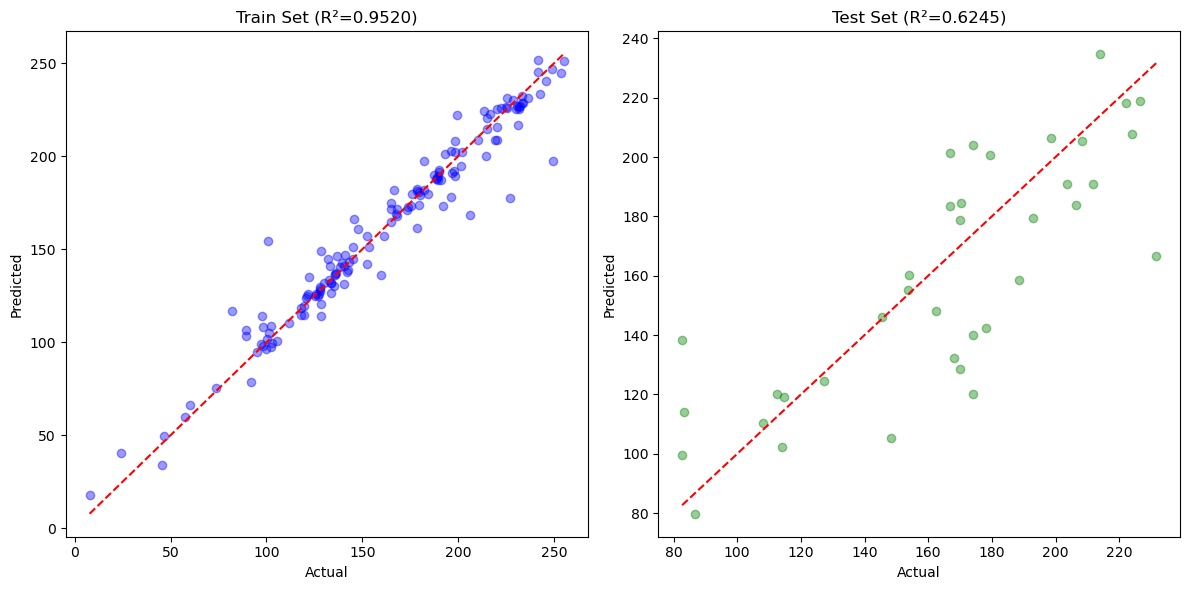

In [ ]:
import pandas as pd 
import numpy as np
import warnings
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
import xgboost as xgb
import optuna
import matplotlib.pyplot as plt
import joblib

warnings.filterwarnings('ignore')

# ==========================
# Step 1: Read a single data file.
# ==========================
data_df = pd.read_csv(str(ARCHIVE_INPUT_DIR / "original_m0_dh.csv"))

# ==========================
# Step 2: Select features and targets without standardization.
#       Omit the first column and use the last column as the target.
# ==========================
X_df = data_df.iloc[:, 1:-1]
y = data_df.iloc[:, -1]

# Coerce targets to numeric; nonnumeric entries become NaN.
y = pd.to_numeric(y, errors='coerce').astype(np.float32)

# Drop rows with missing targets.
mask = ~np.isnan(y)
X_df = X_df.loc[mask].reset_index(drop=True)
y = y[mask].reset_index(drop=True)

# ==========================
# Step 3: One-hot encode features and split into training/test sets.
# ==========================
# Encode the full feature table to keep the columns consistent.
X_df = pd.get_dummies(X_df, drop_first=True).apply(pd.to_numeric)

# Split into training/test sets (8:2, controlled by test_size).
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_df, y, test_size=0.2, random_state=42
)

# This alignment is a no-op after joint encoding.
X_test_raw = X_test_raw.reindex(columns=X_train_raw.columns, fill_value=0)

# Convert the DataFrame to a NumPy array (float32).
X_train = X_train_raw.values.astype(np.float32)
X_test = X_test_raw.values.astype(np.float32)
y_train = y_train.values.astype(np.float32)
y_test = y_test.values.astype(np.float32)

print(f"Training samples: {X_train.shape[0]}, Features: {X_train.shape[1]}")
print(f"Test samples: {X_test.shape[0]}")

# ==========================
# Step 4: Define the Optuna objective (KFold + early stopping).
# ==========================
def optimize(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 900, 1800),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.05),
        'max_depth': trial.suggest_int('max_depth', 4, 5),
        'min_child_weight': trial.suggest_int('min_child_weight', 2, 10),
        'subsample': trial.suggest_float('subsample', 0.70, 0.86),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.58, 0.72),
        'gamma': trial.suggest_float('gamma', 1.2, 3.5),
        'reg_lambda': trial.suggest_float('reg_lambda', 18, 90),
        'reg_alpha': trial.suggest_float('reg_alpha', 18, 70),
        'objective': 'reg:squarederror',
        'random_state': 42
    }

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    losses = []

    for train_idx, valid_idx in kf.split(X_train):
        X_train_cv, X_valid_cv = X_train[train_idx], X_train[valid_idx]
        y_train_cv, y_valid_cv = y_train[train_idx], y_train[valid_idx]

        model = xgb.XGBRegressor(**params)
        model.fit(X_train_cv, y_train_cv)

        y_pred = model.predict(X_valid_cv)
        rmse = root_mean_squared_error(y_valid_cv, y_pred)
        losses.append(rmse)

    return np.mean(losses)

# Step 5: Run Optuna.
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(optimize, n_trials=800)

print("\n✅ Best parameters:", study.best_params)
print(f"✅ Best CV RMSE: {study.best_value:.2f}")

# Step 6: Train the final model.
best_model = xgb.XGBRegressor(**study.best_params, objective='reg:squarederror', random_state=42)
best_model.fit(X_train, y_train)

# Step 7: Save the model.
joblib.dump(best_model, "best_model_xgb_refined.pkl")

# Step 8: Evaluate the model.
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

rmse_train = root_mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)
rmse_test = root_mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

print(f"\n📊 Train RMSE: {rmse_train:.2f}, R²: {r2_train:.4f}")
print(f"📊 Test RMSE: {rmse_test:.2f}, R²: {r2_test:.4f}")

# Step 9: Visualize results.
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(y_train, y_train_pred, alpha=0.4, color='blue')
plt.plot([min(y_train), max(y_train)], [min(y_train), max(y_train)], 'r--')
plt.title(f"Train Set (R²={r2_train:.4f})")
plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_test_pred, alpha=0.4, color='green')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
plt.title(f"Test Set (R²={r2_test:.4f})")
plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.tight_layout()
plt.savefig("optuna_xgb_refined_result.png", dpi=300)
plt.show()


In [ ]:
# ==========================
# Locate the test sample with the largest prediction error.
# Run the preceding training cell first to define best_model and y_test_pred.
# ==========================

import numpy as np
from sklearn.model_selection import train_test_split

# Compute y_test_pred if it is not yet available in this session.
try:
    y_test_pred
except NameError:
    y_test_pred = best_model.predict(X_test)

# Compute absolute test-set errors.
abs_err = np.abs(y_test_pred - y_test)
outlier_pos_in_test = int(np.argmax(abs_err))

# Recreate the split to obtain test indices in the cleaned data.
all_idx = np.arange(len(y))
_, idx_test = train_test_split(all_idx, test_size=0.2, random_state=42)
clean_idx = int(idx_test[outlier_pos_in_test])

# Map the cleaned-data indices back to the original CSV rows.
orig_idx = np.where(mask.values)[0][clean_idx] if hasattr(mask, 'values') else np.where(mask)[0][clean_idx]
row = data_df.iloc[int(orig_idx)]

print("=== Largest test-set outlier ===")
print(f"Position in test set: {outlier_pos_in_test}")
print(f"Original CSV row index (0-based): {int(orig_idx)}")
print(f"Original CSV row number (1-based, add +1 for header): {int(orig_idx) + 2}")
print(f"Actual: {float(y_test[outlier_pos_in_test]):.4f}")
print(f"Predicted: {float(y_test_pred[outlier_pos_in_test]):.4f}")
print(f"Absolute Error: {float(abs_err[outlier_pos_in_test]):.4f}")

print("\nOriginal record:")
print(row)

=== Largest test-set outlier ===
Position in test set: 34
Original CSV row index (0-based): 66
Original CSV row number (1-based, add +1 for header): 68
Actual: 57.6100
Predicted: 129.5748
Absolute Error: 71.9648

Original record:
ID1-salt                            CH3COONa·3H2O
1-Tm (°C)                                    58.0
1-ΔHm (J/g)                                 272.0
1-Molecular Weight                         136.08
1-Hydrogen Bond Donor Count                     3
1-Hydrogen Bond Acceptor Count                  5
1-Topological Polar Surface Area             43.1
1-Heavy Atom Count                              8
1-Complexity                                 34.6
1-Covalently-Bonded Unit Count                  5
1-Hydration Number                              3
1-Elem_H                                        9
1-Elem_O                                        5
2-Tm (°C)                                    32.4
2-ΔHm (J/g)                                 249.4
2-Molecular Weight  

Total samples: 192
Mass-fraction columns: ['ID1', 'ID2', 'ID3']
Target column: Enthalpy value (DeltaHm, J g-1)


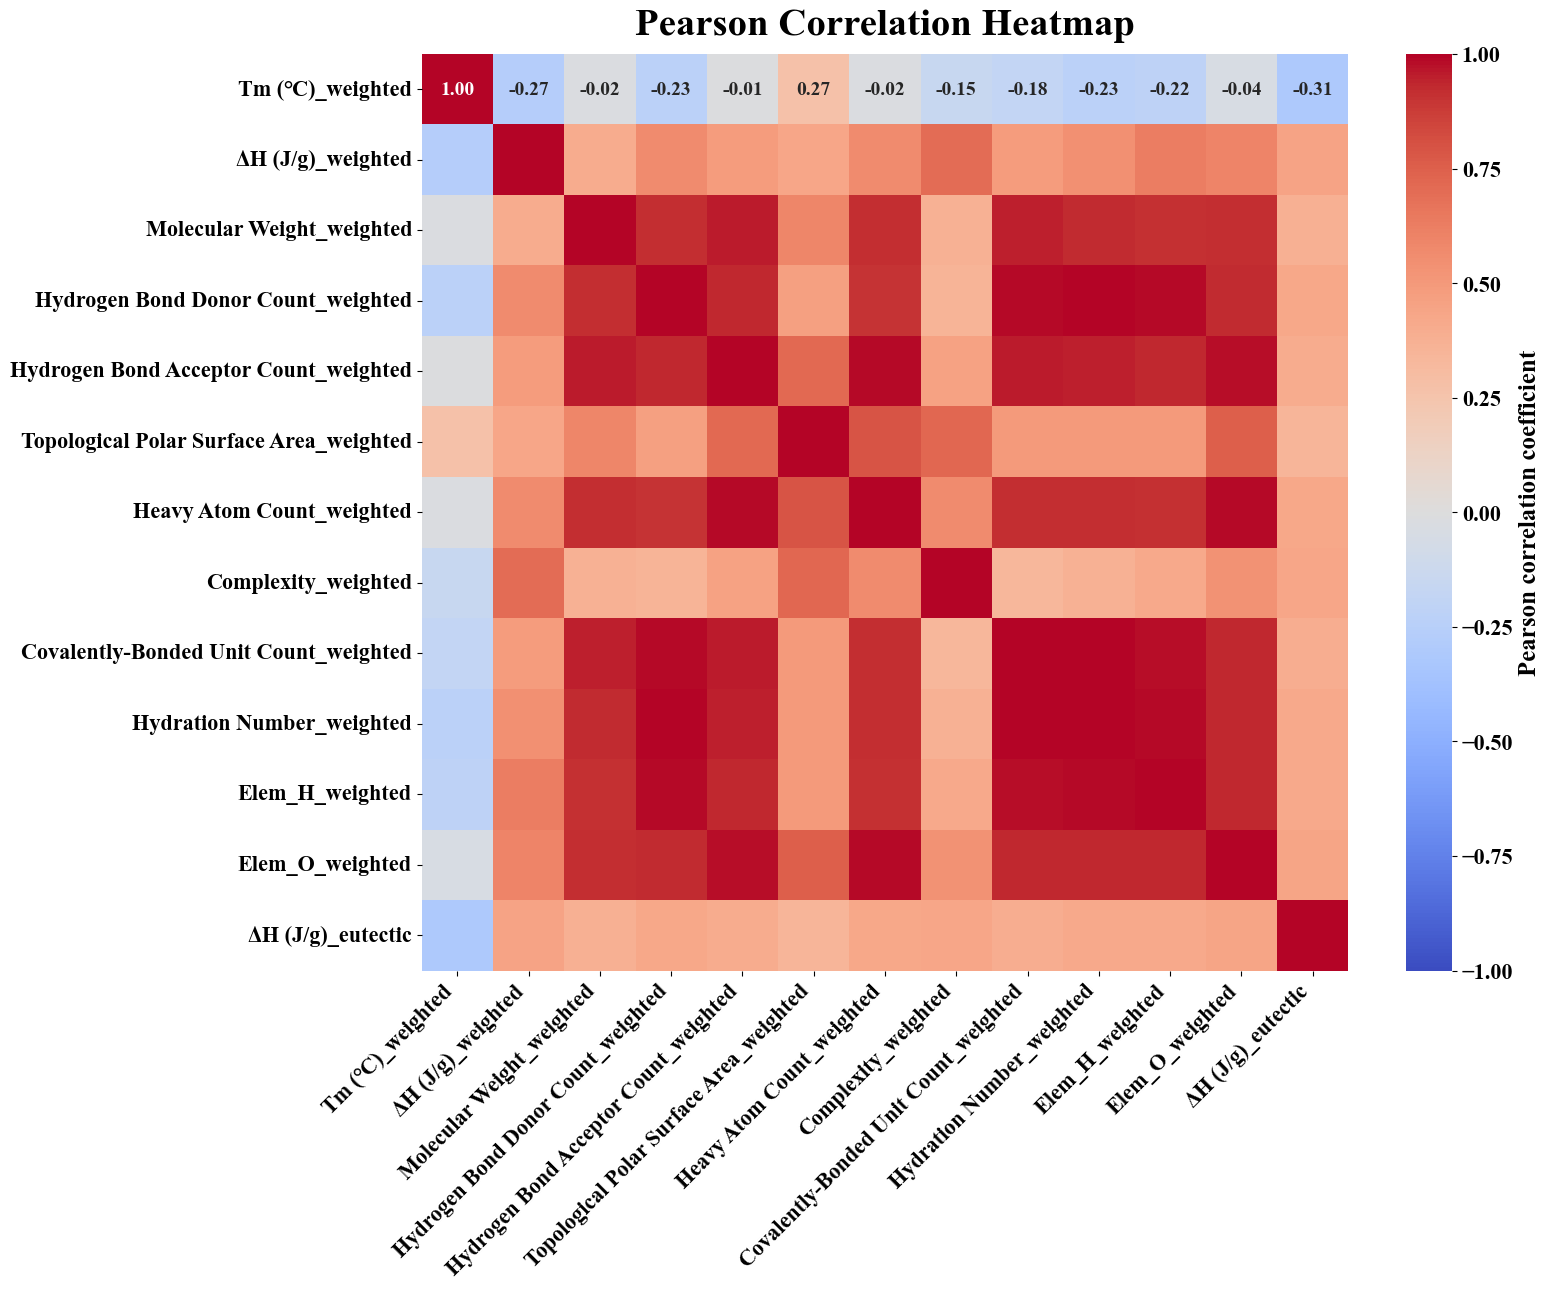

Saved: notebook_outputs/DeltaH_weighted_pearson_heatmap_all_samples.png


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================
# Enthalpy Pearson correlation heatmap (all samples).
# weighted = ID1*salt1_feature + ID2*salt2_feature + ID3*salt3_feature
# White background, Times New Roman, and large bold text.
# =====================================
file_path = str(ARCHIVE_INPUT_DIR / "original_m0_dh.csv")
df = pd.read_csv(file_path)

# Global style: Times New Roman and large bold text.
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titlesize"] = 28
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16

# Fixed CSV column structure:
# [0] salt name | [1:13] component-1 features | [13:25] component-2 features | [25:37] component-3 features
# [37:40] ID1/ID2/ID3 | [40] enthalpy target
ratio_cols = [df.columns[37], df.columns[38], df.columns[39]]
target_col = df.columns[40]

feature_names = [
    "Tm (℃)",
    "ΔH (J/g)",
    "Molecular Weight",
    "Hydrogen Bond Donor Count",
    "Hydrogen Bond Acceptor Count",
    "Topological Polar Surface Area",
    "Heavy Atom Count",
    "Complexity",
    "Covalently-Bonded Unit Count",
    "Hydration Number",
    "Elem_H",
    "Elem_O",
]

# Use all samples without filtering on ID3.
all_df = df.copy()
for c in all_df.columns:
    all_df[c] = pd.to_numeric(all_df[c], errors="ignore")

# Generate mass-fraction-weighted features.
r1 = pd.to_numeric(all_df[ratio_cols[0]], errors="coerce")
r2 = pd.to_numeric(all_df[ratio_cols[1]], errors="coerce")
r3 = pd.to_numeric(all_df[ratio_cols[2]], errors="coerce")

weighted_df = pd.DataFrame(index=all_df.index)
for i, feat in enumerate(feature_names):
    f1 = pd.to_numeric(all_df.iloc[:, 1 + i], errors="coerce")
    f2 = pd.to_numeric(all_df.iloc[:, 13 + i], errors="coerce")
    f3 = pd.to_numeric(all_df.iloc[:, 25 + i], errors="coerce")

    weighted_df[f"{feat}_weighted"] = r1 * f1 + r2 * f2 + r3 * f3

# Use enthalpy as the target.
weighted_df["ΔH (J/g)_eutectic"] = pd.to_numeric(all_df[target_col], errors="coerce")
weighted_df = weighted_df.dropna(axis=0, how="any")

print(f"Total samples: {weighted_df.shape[0]}")
print("Mass-fraction columns:", ratio_cols)
print("Target column:", target_col)

# Pearson correlation matrix.
corr = weighted_df.corr(method="pearson")

# Annotate only the first row, following the existing plot style.
annot_mat = np.full(corr.shape, "", dtype=object)
annot_mat[0, :] = [f"{v:.2f}" for v in corr.iloc[0, :].values]

# White plotting canvas.
fig, ax = plt.subplots(figsize=(16, 13))

hm = sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    annot=annot_mat,
    fmt="",
    annot_kws={"size": 14, "family": "Times New Roman", "weight": "bold"},
    square=False,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)

ax.set_title("Pearson Correlation Heatmap", fontsize=28, pad=14, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

# Use bold axis labels.
for t in ax.get_xticklabels():
    t.set_fontweight("bold")
for t in ax.get_yticklabels():
    t.set_fontweight("bold")

# Use bold colorbar labels.
cbar = hm.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)
for t in cbar.ax.get_yticklabels():
    t.set_fontweight("bold")
cbar.set_label("Pearson correlation coefficient", size=18, weight="bold")

plt.tight_layout()
out_png = str(ARCHIVE_OUTPUT_DIR / "DeltaH_weighted_pearson_heatmap_all_samples.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", out_png)

In [ ]:
# Random-forest regression of eutectic melting temperature.
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
import joblib

# 1) Read the data.
file_path = str(ARCHIVE_INPUT_DIR / "original_m0_tm.csv")
data_df = pd.read_csv(file_path)

# 2) Select features and target (last column: melting temperature).
X_df = data_df.iloc[:, :-1].copy()
y = pd.to_numeric(data_df.iloc[:, -1], errors="coerce")

# 3) Drop rows with missing targets.
mask = ~y.isna()
X_df = X_df.loc[mask].reset_index(drop=True)
y = y.loc[mask].reset_index(drop=True)

# 4) Encode categorical features and convert to numeric.
X_df = pd.get_dummies(X_df, drop_first=True)
X_df = X_df.apply(pd.to_numeric, errors="coerce")
X_df = X_df.fillna(0)

# 5) Split into training/test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X_df, y, test_size=0.2, random_state=42
)

# 6) Train the random-forest regressor.
rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# 7) Evaluate the model.
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

rmse_train = root_mean_squared_error(y_train, y_train_pred)
rmse_test = root_mean_squared_error(y_test, y_test_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print("=== Random-forest regression (melting temperature) ===")
print(f"Training RMSE: {rmse_train:.4f}")
print(f"Test RMSE: {rmse_test:.4f}")
print(f"Training R²:   {r2_train:.4f}")
print(f"Test R²:   {r2_test:.4f}")

# 8) Save the model.
joblib.dump(rf_model, "best_model_rf_melting.pkl")
print("Model saved to: best_model_rf_melting.pkl")